In [1]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.1          # time step (ms)
v_rest = -52.0    # resting voltage (mV)
v_reset = -52.0   # voltage right after a spike (mV)
v_th = -45.0      # threshold: fire when voltage reaches this (mV)
tau_m = 20.0      # how slowly the bucket leaks (ms)
tau_syn = 5.0     # how quickly a synaptic tap fades (ms)
t_ref = 2.2       # refractory period after a spike (ms)
w_syn = 0.275     # strength of ONE synapse (mV)

In [2]:
def simulate_one_neuron(n_synapses, input_rate_hz=100, duration_ms=300, seed=0):
    steps = int(duration_ms / dt)
    rng = np.random.default_rng(seed)
    input_spikes = rng.random(steps) < input_rate_hz * dt / 1000

    w = n_synapses * w_syn
    v, g, ref = v_rest, 0.0, 0
    voltages, spike_times = [], []

    for t in range(steps):
        if input_spikes[t]:
            g += w

        v += dt * (v_rest - v + g) / tau_m
        g -= dt * g / tau_syn

        if ref > 0:
            v = v_reset
            ref -= 1
        elif v >= v_th:
            spike_times.append(t * dt)
            v = v_reset
            ref = int(t_ref / dt)

        voltages.append(v)

    return np.array(voltages), spike_times, input_spikes

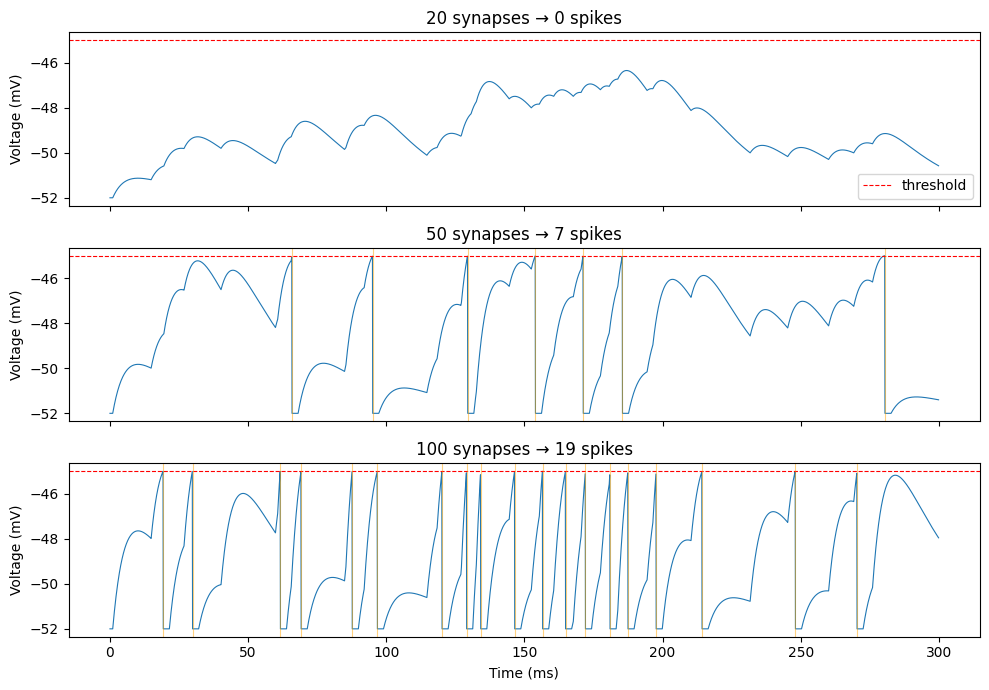

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
time = np.arange(int(300 / dt)) * dt

for ax, n_syn in zip(axes, [20, 50, 100]):
    voltages, spike_times, input_spikes = simulate_one_neuron(n_syn)
    ax.plot(time, voltages, linewidth=0.8)
    ax.axhline(v_th, color="red", linestyle="--", linewidth=0.8, label="threshold")
    for st in spike_times:
        ax.axvline(st, color="orange", alpha=0.5, linewidth=0.8)
    ax.set_title(f"{n_syn} synapses → {len(spike_times)} spikes")
    ax.set_ylabel("Voltage (mV)")

axes[-1].set_xlabel("Time (ms)")
axes[0].legend()
plt.tight_layout()
plt.show()

In [4]:
delay = 1.8           # synaptic delay (ms)
stim_rate = 150.0     # how fast stimulated neurons receive input (Hz)
stim_strength = 250 * w_syn   # strength of the artificial input

def simulate_network(W, stim, duration_ms=500, seed=0):
    n = W.shape[0]
    steps = int(duration_ms / dt)
    delay_steps = int(delay / dt)
    ref_steps = int(t_ref / dt)
    rng = np.random.default_rng(seed)

    v = np.full(n, v_rest)
    g = np.zeros(n)
    ref = np.zeros(n, dtype=int)
    buffer = np.zeros((delay_steps, n))
    spike_counts = np.zeros(n, dtype=int)
    W_mv = W * w_syn

    for t in range(steps):
        slot = t % delay_steps
        g += buffer[slot]
        buffer[slot] = 0

        hits = stim[rng.random(len(stim)) < stim_rate * dt / 1000]
        g[hits] += stim_strength

        v += dt * (v_rest - v + g) / tau_m
        g -= dt * g / tau_syn

        refractory = ref > 0
        v[refractory] = v_reset
        ref[refractory] -= 1

        fired = np.flatnonzero((v >= v_th) & ~refractory)
        v[fired] = v_reset
        ref[fired] = ref_steps
        spike_counts[fired] += 1

        if len(fired) > 0:
            buffer[slot] += W_mv[fired].sum(axis=0)

    return spike_counts / (duration_ms / 1000)

In [5]:
names = ["A", "B", "C", "I"]
A, B, C, I = 0, 1, 2, 3

W_small = np.zeros((4, 4))
W_small[A, B] = 100
W_small[B, C] = 100
W_small[I, C] = -150

rates = simulate_network(W_small, stim=np.array([A]))
print("Stimulate A:        ", dict(zip(names, rates)))

rates = simulate_network(W_small, stim=np.array([A, I]))
print("Stimulate A and I:  ", dict(zip(names, rates)))

Stimulate A:         {'A': np.float64(178.0), 'B': np.float64(104.0), 'C': np.float64(60.0), 'I': np.float64(0.0)}
Stimulate A and I:   {'A': np.float64(142.0), 'B': np.float64(80.0), 'C': np.float64(0.0), 'I': np.float64(164.0)}


In [6]:
print(dict(zip(names, [float(r) for r in rates])))

{'A': 142.0, 'B': 80.0, 'C': 0.0, 'I': 164.0}
